# Zero-shot analysis

Text-prompt zero-shot phase recognition with the vision-language encoders (HecVL, SurgVLP, PeskaVLP, SurgCLIP): how well phase prompts alone classify frames, and where they fail. Reads evaluation CSVs and per-frame prediction files only; zero-shot runs through the `evaluate` task.

## Setup

Imports, paths, models, sampling rates and prompt styles.

In [1]:
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import entropy
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_fscore_support
from torchmetrics.functional.classification import multiclass_calibration_error

from surgphase.config import MODELS, PHASE_GROUP_FILE, PROMPTS_FILE, RESULTS_DIR, ROOT_DIR, UNLABELLED
from surgphase.data import PhaseMapper, load_phase_group, load_prompts, load_surgeries, merge_phases
from surgphase.eval import load_predictions, score
from surgphase.temporal import HMM_METHODS, Decoding, leave_one_out_hmms
from surgphase.viz import CATEGORICAL, NEUTRAL, SEQUENTIAL, phase_colors, plot_confusion_matrix, plot_timeline, style_axes
from surgphase.viz.style import GRIDLINE, INK, MUTED_INK, SECONDARY_INK, SURFACE

RUN_DIR = RESULTS_DIR / "evaluation" / "zeroshot"
EVALUATE_COMMAND = (
    "uv run poe evaluate --annotations assets/annotations/default/annotated_frames.csv --fps 1 15 --merge P5+P6 "
    "--models HecVL SurgVLP PeskaVLP SurgCLIP --sources zeroshot --preprocessor letterbox --centered "
    "--output-dir results/evaluation/zeroshot"
)
NEUTRAL_PHASE = "P0"
SUMMARY_METRICS = ["accuracy", "f1_macro", "edit_score", "f1_at_25"]
CHANCE_SEED = 0
CALIBRATION_BINS = 15
CONFIDENCE_BINS = 30
TIMELINE_FPS = 1.0

MODEL_COLORS = {model: CATEGORICAL[index] for index, model in enumerate(MODELS)}


def resolve(path):
    path = Path(path)
    return path if path.is_absolute() else ROOT_DIR / path


def decoding_of(row):
    window = None if pd.isna(row.window_seconds) else float(row.window_seconds)
    return Decoding(row.method, window, bool(row.causal))


def decoding_label(decoding):
    if decoding.window_seconds is None:
        return decoding.method
    return f"{decoding.method} {decoding.window_seconds:g}s{'' if decoding.causal else ' centred'}"


def key_label(key):
    return f"{key[0]} @ {key[1]:g} fps" + (f" ({key[2]})" if len(key) > 2 else "")


def clean_axes(ax, grid_axis="y"):
    style_axes(ax)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRIDLINE, linewidth=0.6)
    ax.set_axisbelow(True)


def figure_legend(fig, axes):
    handles = {}
    for ax in np.ravel(axes):
        for handle, label in zip(*ax.get_legend_handles_labels(), strict=True):
            handles.setdefault(label, handle)
    fig.legend(
        list(handles.values()), list(handles), loc="outside lower center", ncol=min(len(handles), 6),
        frameon=False, labelcolor=SECONDARY_INK,
    )


def annotate_heatmap(ax, values, fmt="{:.2f}"):
    for (row, column), value in np.ndenumerate(values):
        if np.isfinite(value):
            ax.text(column, row, fmt.format(value), ha="center", va="center", fontsize=8, color=SURFACE if value > 0.6 else INK)

## Load results

Zero-shot rows from the evaluation CSVs, per-frame probabilities from the prediction files and the aligned per-frame phase labels.

In [2]:
metrics_file = RUN_DIR / "metrics.csv"
if not metrics_file.is_file():
    raise FileNotFoundError(f"no evaluation run in {RUN_DIR}, create it with:\n{EVALUATE_COMMAND}")
run = json.loads((RUN_DIR / "run.json").read_text(encoding="utf-8"))
merges = [tuple(ids) for ids in run["merge"]]

phase_group = merge_phases(load_phase_group(PHASE_GROUP_FILE), merges)
mapper = PhaseMapper(phase_group)
phase_ids = mapper.get_all_phase_ids()
phase_names = [f"{phase.id} {phase.name}" for phase in mapper.phases]
num_phases = len(phase_ids)
colors = phase_colors(num_phases, neutral_phase=mapper.map_to_index(NEUTRAL_PHASE) if NEUTRAL_PHASE in phase_ids else None)

results = pd.read_csv(metrics_file)
results = results[results["source"] == "zeroshot"].reset_index(drop=True)
if results.empty:
    raise ValueError(f"{metrics_file} has no zeroshot rows, create them with:\n{EVALUATE_COMMAND}")
results["decoding"] = [decoding_label(decoding_of(row)) for row in results.itertuples()]
decoding_order = list(dict.fromkeys(results["decoding"]))
decodings_by_label = {label: decoding_of(row) for label, row in zip(results["decoding"], results.itertuples())}

styles = run["prompt_styles"]
variants = [*styles, "+".join(styles)] if len(styles) > 1 else list(styles)
models = [model for model in MODELS if model in set(results["model"])]
fps_values = sorted(results["fps"].unique())
raw = results[results["method"] == "none"]

surgeries = {
    fps: load_surgeries(resolve(run["annotations"]), phase_group, ROOT_DIR, fps, run["surgeries"], merges)
    for fps in fps_values
}
labels = {fps: {surgery_id: surgery.labels for surgery_id, surgery in by_id.items()} for fps, by_id in surgeries.items()}

probabilities = {
    (row.model, row.fps, row.variant): load_predictions(RUN_DIR / "predictions" / row.predictions_file)
    for row in results.drop_duplicates(["model", "fps", "variant"]).itertuples()
}
keys = sorted(probabilities, key=lambda key: (models.index(key[0]), key[1], variants.index(key[2])))

misaligned = [
    (key_label(key), surgery_id)
    for key, by_id in probabilities.items()
    for surgery_id, p in by_id.items()
    if len(p) != len(labels[key[1]][surgery_id])
]
if misaligned:
    raise ValueError(f"prediction and label lengths differ for {misaligned}")


def pooled(key):
    by_id = probabilities[key]
    y = np.concatenate([labels[key[1]][surgery_id] for surgery_id in by_id])
    p = np.concatenate([by_id[surgery_id] for surgery_id in by_id])
    keep = y != UNLABELLED
    return y[keep], p[keep]


print(
    f"{len(results):,} zero-shot rows from {RUN_DIR.relative_to(ROOT_DIR) if RUN_DIR.is_relative_to(ROOT_DIR) else RUN_DIR}\n"
    f"phase group {phase_group.name} ({num_phases} classes), models {', '.join(models)}, "
    f"fps {', '.join(f'{fps:g}' for fps in fps_values)}, variants {', '.join(variants)}, "
    f"{len(decoding_order)} decodings, {results['surgery_id'].nunique()} surgeries"
)

3,024 zero-shot rows from results/evaluation/zeroshot
phase group default_P5+P6 (6 classes), models HecVL, SurgVLP, PeskaVLP, SurgCLIP, fps 1, 15, variants narrative, descriptive, narrative+descriptive, 18 decodings, 7 surgeries


## Prompt inventory

Prompts per phase and style (descriptive, narrative): counts, lengths and examples.

In [3]:
prompts = load_prompts(resolve(run.get("prompts", PROMPTS_FILE)))
prompt_table = pd.DataFrame(
    [
        {
            "class": phase.id,
            "phase": member,
            "style": style,
            "prompt": prompt.id,
            "message": prompt.message,
            "words": len(prompt.message.split()),
        }
        for phase in mapper.phases
        for member in phase.members
        for style in styles
        for prompt in getattr(prompts[member], style)
    ]
)

for phase in mapper.phases:
    source = f" (prompts from {' + '.join(phase.members)})" if len(phase.members) > 1 else ""
    print(f"{phase.id} {phase.name}{source}")
    for style in styles:
        example = getattr(prompts[phase.members[0]], style)[0]
        print(textwrap.fill(f"{style}: {example.message}", width=110, initial_indent="  ", subsequent_indent="    "))

prompt_inventory = (
    prompt_table.groupby(["class", "style"])["words"].agg(prompts="count", words="mean").unstack("style").reindex(phase_ids)
)
prompt_inventory.columns = [f"{style} {stat}" for stat, style in prompt_inventory.columns]
prompt_inventory.insert(0, "name", [phase.name for phase in mapper.phases])
prompt_inventory.insert(1, "members", ["+".join(phase.members) for phase in mapper.phases])
prompt_inventory.round(1)

P0 No surgical activity
  narrative: The camera is out of the patient and I am cleaning the lens.
  descriptive: A blurred, dark or out-of-body camera image with no recognisable anatomy.
P1 Preparation
  narrative: I start with an overview of the groin and the intact peritoneum.
  descriptive: A wide panoramic view of the groin with smooth, shiny, intact peritoneum.
P2 Peritoneal flap incision
  narrative: I open the peritoneum with the cautery hook above the hernia orifice.
  descriptive: An electrocautery hook cuts the peritoneum, producing smoke and a thin burnt line.
P3 Peritoneal flap dissection
  narrative: I take the peritoneal flap down bluntly and expose the preperitoneal fat.
  descriptive: A grasper pulls the peritoneal flap downward, exposing a large field of yellow fat.
P4 Hernia dissection
  narrative: I pull the hernia sac out of the internal ring with traction on both sides.
  descriptive: A white funnel-shaped hernia sac is pulled out of the internal inguinal ring.
P5 

,name,members,descriptive prompts,narrative prompts,descriptive words,narrative words
class,,,,,,
P0,No surgical activity,P0,3,3,12.0,13.3
P1,Preparation,P1,3,3,13.7,13.0
P2,Peritoneal flap incision,P2,3,3,14.0,14.0
P3,Peritoneal flap dissection,P3,3,3,13.3,13.0
P4,Hernia dissection,P4,3,3,13.3,13.3
P5,Mesh deployment,P5+P6,6,6,19.5,17.3


## Overall performance

Accuracy and macro F1 per model and FPS without temporal decoding, against chance and majority-class baselines.

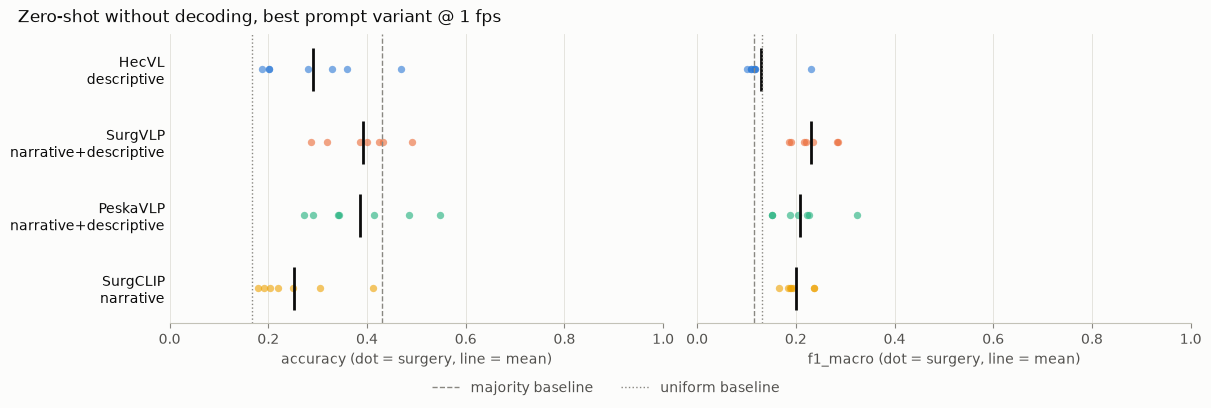

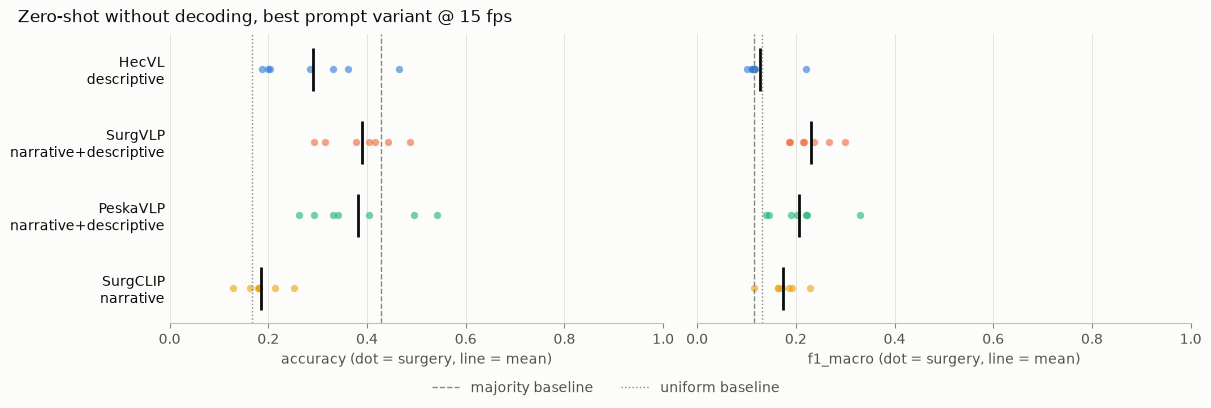

variant  accuracy  f1_macro  edit_score  \
model             fps                                                           
HecVL             1.0             descriptive     0.290     0.129       0.010   
                  15.0            descriptive     0.290     0.127       0.002   
SurgVLP           1.0   narrative+descriptive     0.391     0.231       0.008   
                  15.0  narrative+descriptive     0.391     0.230       0.001   
PeskaVLP          1.0   narrative+descriptive     0.385     0.209       0.010   
                  15.0  narrative+descriptive     0.381     0.207       0.002   
SurgCLIP          1.0               narrative     0.251     0.199       0.057   
                  15.0              narrative     0.185     0.174       0.007   
majority baseline 1.0                     NaN     0.429     0.115       0.198   
                  15.0                    NaN     0.429     0.115       0.198   
uniform baseline  1.0                     NaN     0.168     0.131       0.004   
                  15.0                    NaN     0.168     0.131       0.000   

                        f1_at_25  
model             fps             
HecVL             1.0      0.001  
                  15.0     0.000  
SurgVLP           1.0      0.002  
                  15.0     0.000  
PeskaVLP          1.0      0.005  
                  15.0     0.000  
SurgCLIP          1.0      0.028  
                  15.0     0.001  
majority baseline 1.0      0.282  
                  15.0     0.282  
uniform baseline  1.0      0.000  
                  15.0     0.000

In [4]:
baseline_rows = []
rng = np.random.default_rng(CHANCE_SEED)
for fps in fps_values:
    for surgery_id, y in labels[fps].items():
        others = np.concatenate([other[other != UNLABELLED] for s, other in labels[fps].items() if s != surgery_id])
        majority = np.full_like(y, np.bincount(others, minlength=num_phases).argmax())
        uniform = rng.integers(0, num_phases, size=len(y))
        for name, predicted in (("majority", majority), ("uniform", uniform)):
            result = score(y, predicted)
            baseline_rows.append(
                {"baseline": name, "fps": fps, "surgery_id": surgery_id, **{m: getattr(result, m) for m in SUMMARY_METRICS}}
            )
baselines = pd.DataFrame(baseline_rows)
baseline_summary = baselines.groupby(["baseline", "fps"])[SUMMARY_METRICS].mean()

best_variant = (
    raw.groupby(["model", "fps", "variant"])["f1_macro"].mean().groupby(["model", "fps"]).idxmax().map(lambda index: index[2])
)
best_keys = [(model, fps, best_variant[(model, fps)]) for model in models for fps in fps_values if (model, fps) in best_variant.index]


def best_rows(frame):
    chosen = [best_variant.get((m, f)) == v for m, f, v in zip(frame["model"], frame["fps"], frame["variant"], strict=True)]
    return frame[chosen]


best_raw = best_rows(raw)
best_results = best_rows(results)

for fps in fps_values:
    plot_rows = best_raw[best_raw["fps"] == fps]
    plot_models = [m for m in models if m in set(plot_rows["model"])]
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.55 * len(plot_models) + 1.8), layout="constrained", sharey=True)
    for ax, metric in zip(axes, ("accuracy", "f1_macro"), strict=True):
        clean_axes(ax, grid_axis="x")
        for position, model in enumerate(plot_models):
            values = plot_rows.loc[plot_rows["model"] == model, metric].to_numpy()
            ax.scatter(values, np.full(len(values), position), s=28, color=MODEL_COLORS[model], alpha=0.6, linewidth=0)
            ax.vlines(values.mean(), position - 0.3, position + 0.3, color=INK, linewidth=2)
        for name, style in (("majority", "--"), ("uniform", ":")):
            ax.axvline(baseline_summary.loc[(name, fps), metric], color=MUTED_INK, linestyle=style, linewidth=1, label=f"{name} baseline")
        ax.set_xlim(0, 1)
        ax.set_xlabel(f"{metric} (dot = surgery, line = mean)")
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0, labelcolor=INK)
    axes[0].set_yticks(range(len(plot_models)), labels=[f"{m}\n{best_variant[(m, fps)]}" for m in plot_models])
    axes[0].invert_yaxis()
    figure_legend(fig, axes)
    fig.suptitle(f"Zero-shot without decoding, best prompt variant @ {fps:g} fps", x=0.01, ha="left", color=INK)
    plt.show()

overall = best_raw.groupby(["model", "fps"]).agg(variant=("variant", "first"), **{m: (m, "mean") for m in SUMMARY_METRICS})
overall = pd.concat(
    [
        overall.reindex(models, level="model"),
        baseline_summary.rename(index=lambda name: f"{name} baseline", level="baseline").rename_axis(["model", "fps"]),
    ]
)
overall.round(3)

## Prompt style comparison

Descriptive against narrative prompts, and both combined, per model.

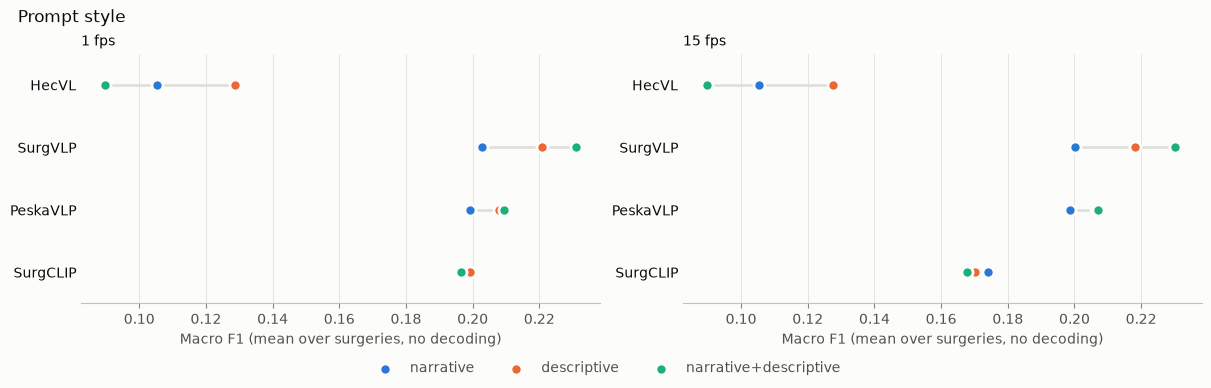

accuracy                                    f1_macro  \
variant       narrative descriptive narrative+descriptive narrative   
model    fps                                                          
HecVL    1.0      0.130       0.290                 0.100     0.105   
         15.0     0.131       0.290                 0.100     0.105   
SurgVLP  1.0      0.337       0.367                 0.391     0.203   
         15.0     0.334       0.367                 0.391     0.200   
PeskaVLP 1.0      0.334       0.406                 0.385     0.199   
         15.0     0.333       0.403                 0.381     0.199   
SurgCLIP 1.0      0.251       0.258                 0.246     0.199   
         15.0     0.185       0.177                 0.170     0.174   

                                                                  best  \
variant       descriptive narrative+descriptive                          
model    fps                                                             
HecVL    1.0        0.129                 0.090            descriptive   
         15.0       0.127                 0.090            descriptive   
SurgVLP  1.0        0.221                 0.231  narrative+descriptive   
         15.0       0.218                 0.230  narrative+descriptive   
PeskaVLP 1.0        0.208                 0.209  narrative+descriptive   
         15.0       0.207                 0.207  narrative+descriptive   
SurgCLIP 1.0        0.199                 0.197              narrative   
         15.0       0.170                 0.168              narrative   

              combined gain  
variant                      
model    fps                 
HecVL    1.0         -0.039  
         15.0        -0.038  
SurgVLP  1.0          0.010  
         15.0         0.012  
PeskaVLP 1.0          0.001  
         15.0         0.001  
SurgCLIP 1.0         -0.003  
         15.0        -0.007

In [5]:
style_scores = raw.pivot_table(index=["model", "fps"], columns="variant", values=["accuracy", "f1_macro"], aggfunc="mean")
style_scores = style_scores.reindex(columns=variants, level="variant").reindex(models, level="model")
style_scores[("best", "")] = best_variant
if len(variants) > 1:
    style_scores[("combined gain", "")] = style_scores[("f1_macro", variants[-1])] - style_scores["f1_macro"][variants[:-1]].max(axis=1)

style_colors = {variant: CATEGORICAL[index] for index, variant in enumerate(variants)}
rows_needed = len(models)
fig, axes = plt.subplots(
    1, len(fps_values), figsize=(6 * len(fps_values), 0.5 * rows_needed + 1.8), layout="constrained", sharex=True, squeeze=False
)
for ax, fps in zip(axes[0], fps_values, strict=True):
    plot_table = style_scores.xs(fps, level="fps")["f1_macro"]
    clean_axes(ax, grid_axis="x")
    positions = np.arange(len(plot_table))
    ax.hlines(positions, plot_table.min(axis=1), plot_table.max(axis=1), color=GRIDLINE, linewidth=2)
    for variant in variants:
        ax.scatter(
            plot_table[variant], positions, s=64, color=style_colors[variant], edgecolor=SURFACE, linewidth=2, zorder=3,
            label=variant,
        )
    ax.set_yticks(positions, labels=plot_table.index)
    ax.set_ylim(rows_needed - 0.5, -0.5)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.set_xlabel("Macro F1 (mean over surgeries, no decoding)")
    ax.set_title(f"{fps:g} fps", loc="left", fontsize=10)
figure_legend(fig, axes)
fig.suptitle("Prompt style", x=0.01, ha="left", color=INK)
plt.show()

style_scores.round(3)

## Per-phase performance

Precision, recall and F1 per phase and model. Which phases the prompts capture and which they miss.

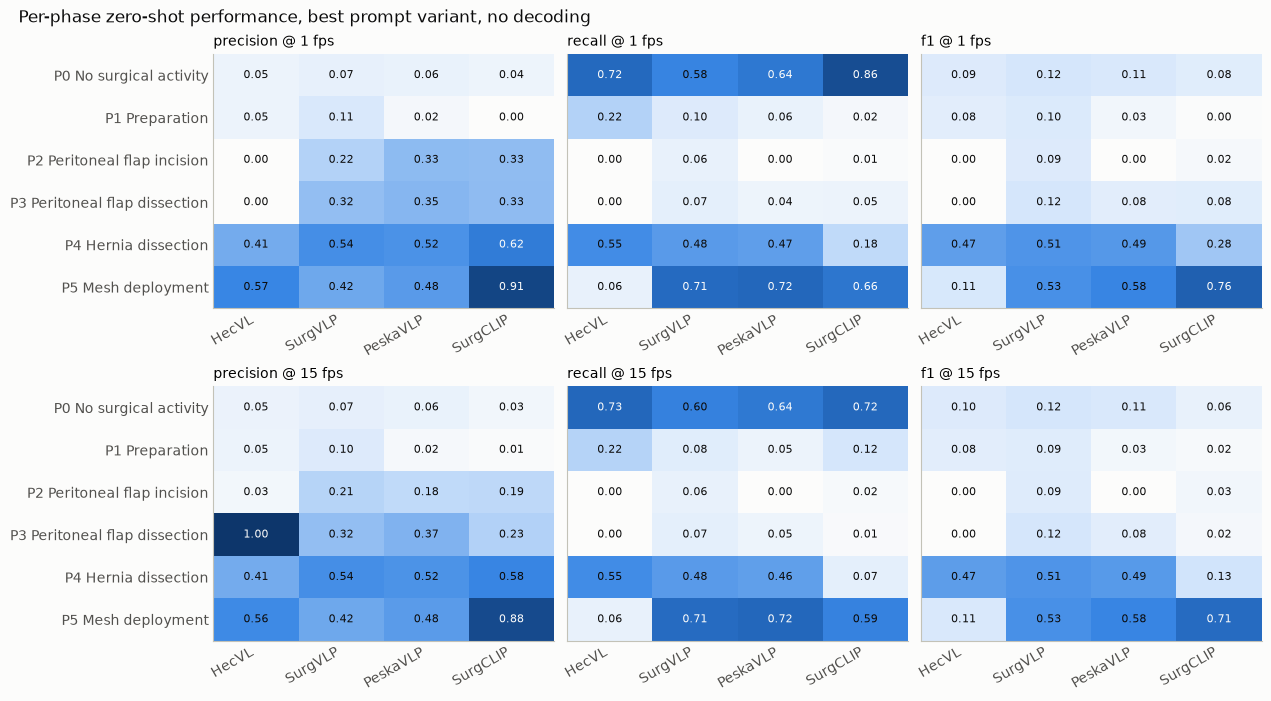

model  HecVL        SurgVLP        PeskaVLP        SurgCLIP       
fps     1.0    15.0    1.0    15.0     1.0    15.0     1.0    15.0
phase                                                             
P0     0.094  0.096   0.118  0.120    0.106  0.106    0.084  0.061
P1     0.080  0.079   0.100  0.089    0.034  0.029    0.004  0.019
P2     0.000  0.000   0.094  0.092    0.001  0.000    0.021  0.033
P3     0.000  0.000   0.120  0.120    0.079  0.081    0.083  0.024
P4     0.467  0.470   0.509  0.508    0.493  0.488    0.280  0.131
P5     0.111  0.106   0.531  0.530    0.578  0.575    0.764  0.706

In [6]:
phase_rows = []
for key in best_keys:
    y, p = pooled(key)
    precision, recall, f1, support = precision_recall_fscore_support(
        y, p.argmax(axis=1), labels=range(num_phases), zero_division=0
    )
    for index, phase in enumerate(phase_ids):
        phase_rows.append(
            {
                "model": key[0],
                "fps": key[1],
                "phase": phase,
                "precision": precision[index],
                "recall": recall[index],
                "f1": f1[index],
                "support": support[index],
            }
        )
per_phase = pd.DataFrame(phase_rows)

phase_metrics = ["precision", "recall", "f1"]
fig, axes = plt.subplots(
    len(fps_values), len(phase_metrics), figsize=(4.2 * len(phase_metrics), 0.45 * num_phases * len(fps_values) + 1.5),
    layout="constrained", squeeze=False,
)
for row, fps in enumerate(fps_values):
    plot_table = per_phase[per_phase["fps"] == fps]
    for ax, metric in zip(axes[row], phase_metrics, strict=True):
        matrix = plot_table.pivot(index="phase", columns="model", values=metric).reindex(index=phase_ids)
        matrix = matrix[[m for m in models if m in matrix.columns]]
        style_axes(ax)
        ax.imshow(matrix.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
        annotate_heatmap(ax, matrix.to_numpy())
        ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns, rotation=30, ha="right")
        ax.set_yticks(range(num_phases), labels=phase_names if ax is axes[row][0] else [""] * num_phases)
        ax.tick_params(length=0)
        ax.set_title(f"{metric} @ {fps:g} fps", loc="left", fontsize=10)
fig.suptitle("Per-phase zero-shot performance, best prompt variant, no decoding", x=0.01, ha="left", color=INK)
plt.show()

per_phase.pivot_table(index="phase", columns=["model", "fps"], values="f1").reindex(index=phase_ids).reindex(
    columns=models, level="model"
).round(3)

## Confusion matrices

Row-normalised confusion matrices per model for the best prompt style.

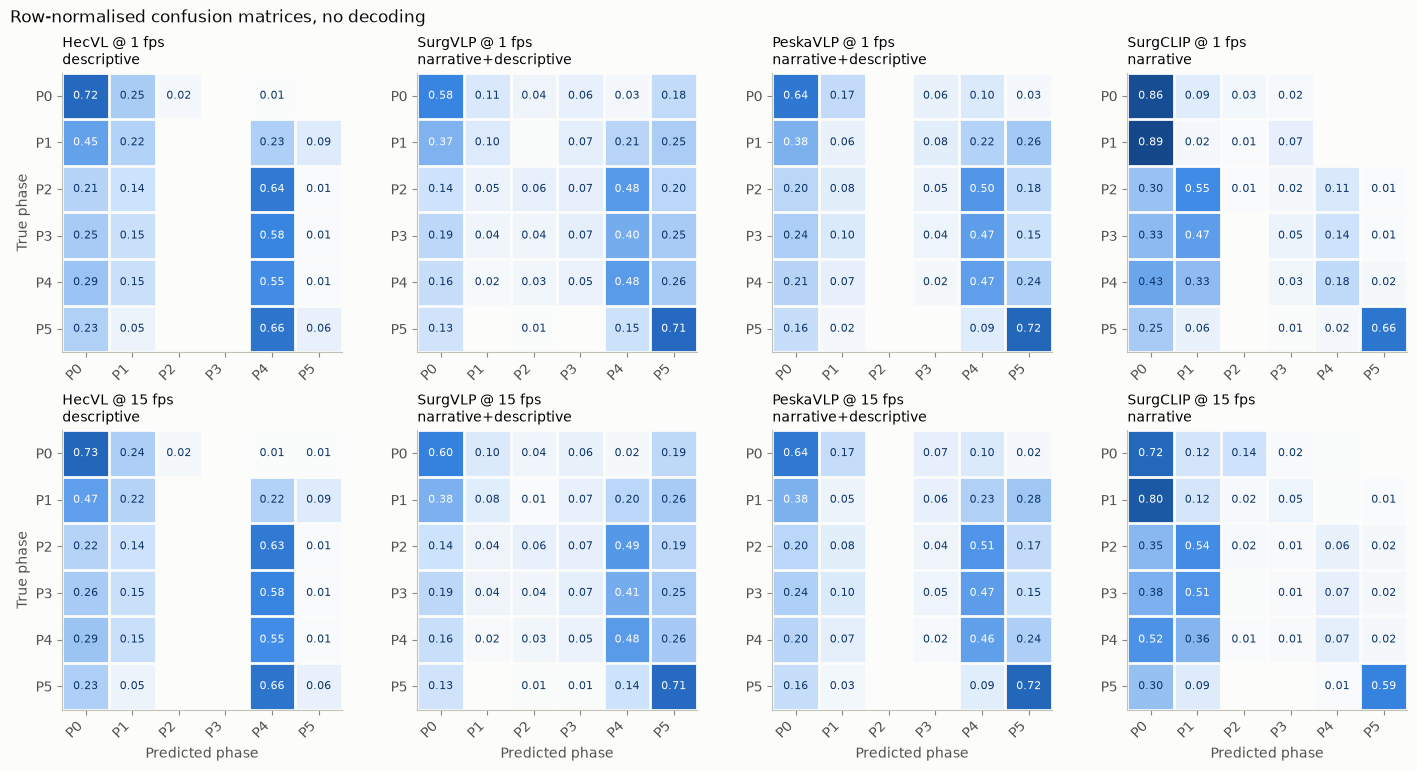

In [7]:
fig, axes = plt.subplots(
    len(fps_values), len(models), figsize=(3.6 * len(models), 3.6 * len(fps_values) + 0.4),
    layout="constrained", squeeze=False,
)
for row, fps in enumerate(fps_values):
    for column, model in enumerate(models):
        ax = axes[row][column]
        key = (model, fps, best_variant.get((model, fps)))
        if key not in probabilities:
            ax.set_visible(False)
            continue
        y, p = pooled(key)
        plot_confusion_matrix(y, p.argmax(axis=1), phase_ids, ax=ax)
        ax.set_title(f"{model} @ {fps:g} fps\n{key[2]}", loc="left", fontsize=10)
        if column:
            ax.set_ylabel("")
        if row < len(fps_values) - 1:
            ax.set_xlabel("")
fig.suptitle("Row-normalised confusion matrices, no decoding", x=0.01, ha="left", color=INK)
plt.show()

## Prediction bias

Predicted phase distribution against the ground truth. Shows whether predictions collapse onto a few phases.

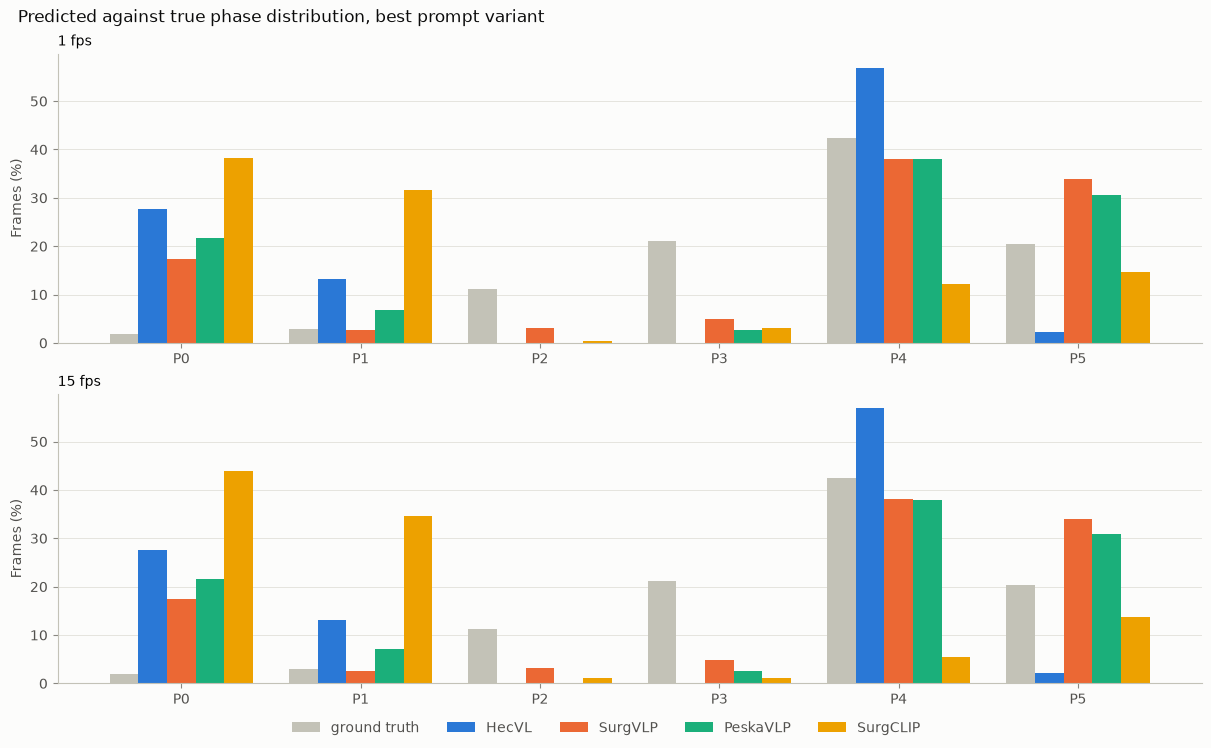

top phase  top share never predicted  \
model    fps  variant                                                      
HecVL    1.0  narrative                    P1      0.737                   
              descriptive                  P4      0.568              P3   
              narrative+descriptive        P1      0.681              P3   
         15.0 narrative                    P1      0.732                   
              descriptive                  P4      0.569                   
              narrative+descriptive        P1      0.677                   
SurgVLP  1.0  narrative                    P5      0.351                   
              descriptive                  P4      0.450                   
              narrative+descriptive        P4      0.380                   
         15.0 narrative                    P5      0.351                   
              descriptive                  P4      0.455                   
              narrative+descriptive        P4      0.381                   
PeskaVLP 1.0  narrative                    P5      0.311                   
              descriptive                  P4      0.467                   
              narrative+descriptive        P4      0.381                   
         15.0 narrative                    P5      0.311                   
              descriptive                  P4      0.464                   
              narrative+descriptive        P4      0.379                   
SurgCLIP 1.0  narrative                    P0      0.382                   
              descriptive                  P0      0.602                   
              narrative+descriptive        P0      0.541                   
         15.0 narrative                    P0      0.440                   
              descriptive                  P0      0.706                   
              narrative+descriptive        P0      0.609                   

                                     normalised entropy  total variation  
model    fps  variant                                                     
HecVL    1.0  narrative                           0.421            0.776  
              descriptive                         0.577            0.504  
              narrative+descriptive               0.496            0.836  
         15.0 narrative                           0.426            0.771  
              descriptive                         0.575            0.505  
              narrative+descriptive               0.500            0.833  
SurgVLP  1.0  narrative                           0.830            0.444  
              descriptive                         0.775            0.189  
              narrative+descriptive               0.775            0.291  
         15.0 narrative                           0.830            0.446  
              descriptive                         0.771            0.193  
              narrative+descriptive               0.774            0.291  
PeskaVLP 1.0  narrative                           0.848            0.443  
              descriptive                         0.679            0.312  
              narrative+descriptive               0.750            0.340  
         15.0 narrative                           0.848            0.444  
              descriptive                         0.679            0.311  
              narrative+descriptive               0.750            0.342  
SurgCLIP 1.0  narrative                           0.779            0.649  
              descriptive                         0.687            0.582  
              narrative+descriptive               0.741            0.624  
         15.0 narrative                           0.703            0.738  
              descriptive                         0.563            0.717  
              narrative+descriptive               0.636            0.752

In [8]:
true_share = {
    fps: np.bincount(np.concatenate([y[y != UNLABELLED] for y in labels[fps].values()]), minlength=num_phases)
    for fps in fps_values
}
true_share = {fps: counts / counts.sum() for fps, counts in true_share.items()}

bias_rows, predicted_share = [], {}
for key in keys:
    y, p = pooled(key)
    share = np.bincount(p.argmax(axis=1), minlength=num_phases) / len(y)
    predicted_share[key] = share
    bias_rows.append(
        {
            "model": key[0],
            "fps": key[1],
            "variant": key[2],
            "top phase": phase_ids[share.argmax()],
            "top share": share.max(),
            "never predicted": ", ".join(phase_ids[i] for i in np.flatnonzero(share == 0)),
            "normalised entropy": entropy(share, base=num_phases),
            "total variation": 0.5 * np.abs(share - true_share[key[1]]).sum(),
        }
    )
bias = pd.DataFrame(bias_rows).set_index(["model", "fps", "variant"])

fig, axes = plt.subplots(
    len(fps_values), 1, figsize=(12, 3.4 * len(fps_values) + 0.6), layout="constrained", sharey=True, squeeze=False
)
for ax, fps in zip(axes[:, 0], fps_values, strict=True):
    clean_axes(ax)
    plot_keys = [key for key in best_keys if key[1] == fps]
    width = 0.8 / (len(plot_keys) + 1)
    positions = np.arange(num_phases)
    ax.bar(positions - 0.4 + width / 2, true_share[fps] * 100, width, color=NEUTRAL, label="ground truth")
    for index, key in enumerate(plot_keys, start=1):
        ax.bar(
            positions - 0.4 + width * (index + 0.5), predicted_share[key] * 100, width, color=MODEL_COLORS[key[0]], label=key[0]
        )
    ax.set_xticks(positions, labels=phase_ids)
    ax.set_ylabel("Frames (%)")
    ax.set_title(f"{fps:g} fps", loc="left", fontsize=10)
figure_legend(fig, axes)
fig.suptitle("Predicted against true phase distribution, best prompt variant", x=0.01, ha="left", color=INK)
plt.show()

bias.reindex(models, level="model").round(3)

## Confidence and calibration

Distribution of the top-class probability for correct and wrong predictions, and reliability per model.

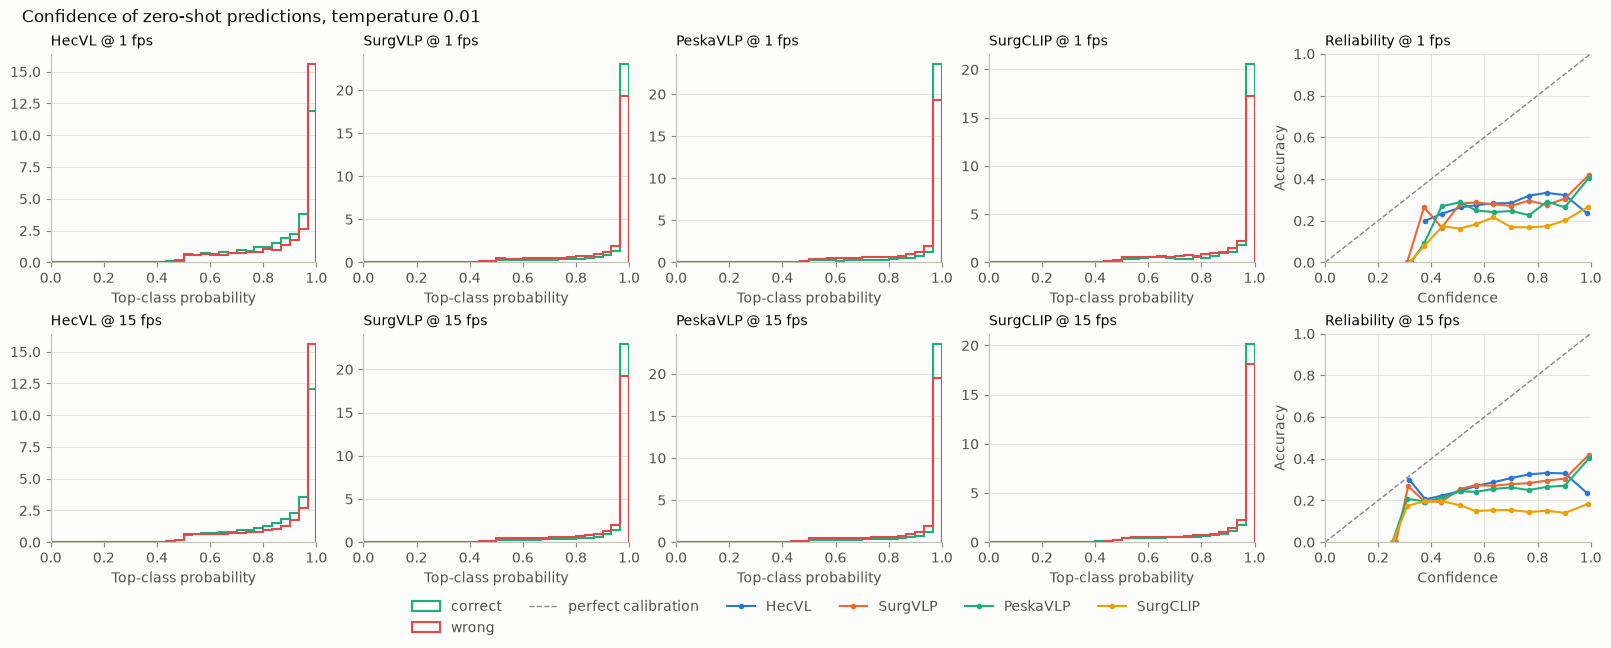

accuracy  mean confidence  \
model    fps  variant                                            
HecVL    1.0  narrative                 0.113            0.945   
              descriptive               0.265            0.890   
              narrative+descriptive     0.087            0.935   
         15.0 narrative                 0.113            0.944   
              descriptive               0.266            0.889   
              narrative+descriptive     0.087            0.934   
SurgVLP  1.0  narrative                 0.319            0.921   
              descriptive               0.386            0.929   
              narrative+descriptive     0.386            0.930   
         15.0 narrative                 0.317            0.921   
              descriptive               0.386            0.928   
              narrative+descriptive     0.385            0.929   
PeskaVLP 1.0  narrative                 0.307            0.914   
              descriptive               0.409            0.942   
              narrative+descriptive     0.369            0.931   
         15.0 narrative                 0.307            0.915   
              descriptive               0.406            0.941   
              narrative+descriptive     0.367            0.933   
SurgCLIP 1.0  narrative                 0.239            0.908   
              descriptive               0.252            0.932   
              narrative+descriptive     0.241            0.917   
         15.0 narrative                 0.174            0.914   
              descriptive               0.170            0.940   
              narrative+descriptive     0.164            0.926   

                                     confidence correct  confidence wrong  \
model    fps  variant                                                       
HecVL    1.0  narrative                           0.922             0.948   
              descriptive                         0.877             0.894   
              narrative+descriptive               0.877             0.941   
         15.0 narrative                           0.921             0.947   
              descriptive                         0.876             0.893   
              narrative+descriptive               0.873             0.940   
SurgVLP  1.0  narrative                           0.945             0.909   
              descriptive                         0.945             0.919   
              narrative+descriptive               0.949             0.917   
         15.0 narrative                           0.943             0.910   
              descriptive                         0.944             0.917   
              narrative+descriptive               0.949             0.917   
PeskaVLP 1.0  narrative                           0.936             0.905   
              descriptive                         0.963             0.928   
              narrative+descriptive               0.952             0.919   
         15.0 narrative                           0.937             0.906   
              descriptive                         0.963             0.926   
              narrative+descriptive               0.953             0.921   
SurgCLIP 1.0  narrative                           0.930             0.901   
              descriptive                         0.945             0.927   
              narrative+descriptive               0.948             0.907   
         15.0 narrative                           0.923             0.912   
              descriptive                         0.954             0.938   
              narrative+descriptive               0.940             0.924   

                                       ECE  
model    fps  variant                       
HecVL    1.0  narrative              0.832  
              descriptive            0.625  
              narrative+descriptive  0.848  
         15.0 narrative              0.831  
              descriptive            0.623  
  

In [9]:
calibration_rows, reliability, confidences = [], {}, {}
for key in keys:
    y, p = pooled(key)
    confidence = p.max(axis=1)
    correct = p.argmax(axis=1) == y
    confidences[key] = confidence, correct
    if correct.any() and not correct.all():
        reliability[key] = calibration_curve(correct, confidence, n_bins=CALIBRATION_BINS)
    calibration_rows.append(
        {
            "model": key[0],
            "fps": key[1],
            "variant": key[2],
            "accuracy": correct.mean(),
            "mean confidence": confidence.mean(),
            "confidence correct": confidence[correct].mean() if correct.any() else np.nan,
            "confidence wrong": confidence[~correct].mean() if not correct.all() else np.nan,
            "ECE": multiclass_calibration_error(
                torch.from_numpy(p).float(), torch.from_numpy(y), num_classes=num_phases, n_bins=CALIBRATION_BINS, norm="l1"
            ).item(),
        }
    )
calibration = pd.DataFrame(calibration_rows).set_index(["model", "fps", "variant"])

bins = np.linspace(0, 1, CONFIDENCE_BINS + 1)
fig, axes = plt.subplots(
    len(fps_values), len(models) + 1, figsize=(3.2 * (len(models) + 1), 2.9 * len(fps_values) + 0.6),
    layout="constrained", squeeze=False,
)
for row, fps in enumerate(fps_values):
    for column, model in enumerate(models):
        ax = axes[row][column]
        key = (model, fps, best_variant.get((model, fps)))
        if key not in confidences:
            ax.set_visible(False)
            continue
        clean_axes(ax)
        confidence, correct = confidences[key]
        ax.hist(confidence[correct], bins=bins, density=True, histtype="step", linewidth=1.5, color=CATEGORICAL[2], label="correct")
        ax.hist(confidence[~correct], bins=bins, density=True, histtype="step", linewidth=1.5, color=CATEGORICAL[7], label="wrong")
        ax.set_xlim(0, 1)
        ax.set_title(f"{model} @ {fps:g} fps", loc="left", fontsize=10)
        ax.set_xlabel("Top-class probability")
    ax = axes[row][-1]
    clean_axes(ax, grid_axis="both")
    ax.plot([0, 1], [0, 1], color=MUTED_INK, linestyle="--", linewidth=1, label="perfect calibration")
    for model in models:
        key = (model, fps, best_variant.get((model, fps)))
        if key in reliability:
            fraction, mean_confidence = reliability[key]
            ax.plot(mean_confidence, fraction, marker="o", markersize=3, color=MODEL_COLORS[model], label=model)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Confidence")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"Reliability @ {fps:g} fps", loc="left", fontsize=10)
figure_legend(fig, axes)
fig.suptitle(
    f"Confidence of zero-shot predictions, temperature {run.get('temperature', 'unknown')}", x=0.01, ha="left", color=INK
)
plt.show()

calibration.reindex(models, level="model").round(3)

## Temporal decoding

Effect of smoothing and HMM decoding on zero-shot predictions, per model and method.

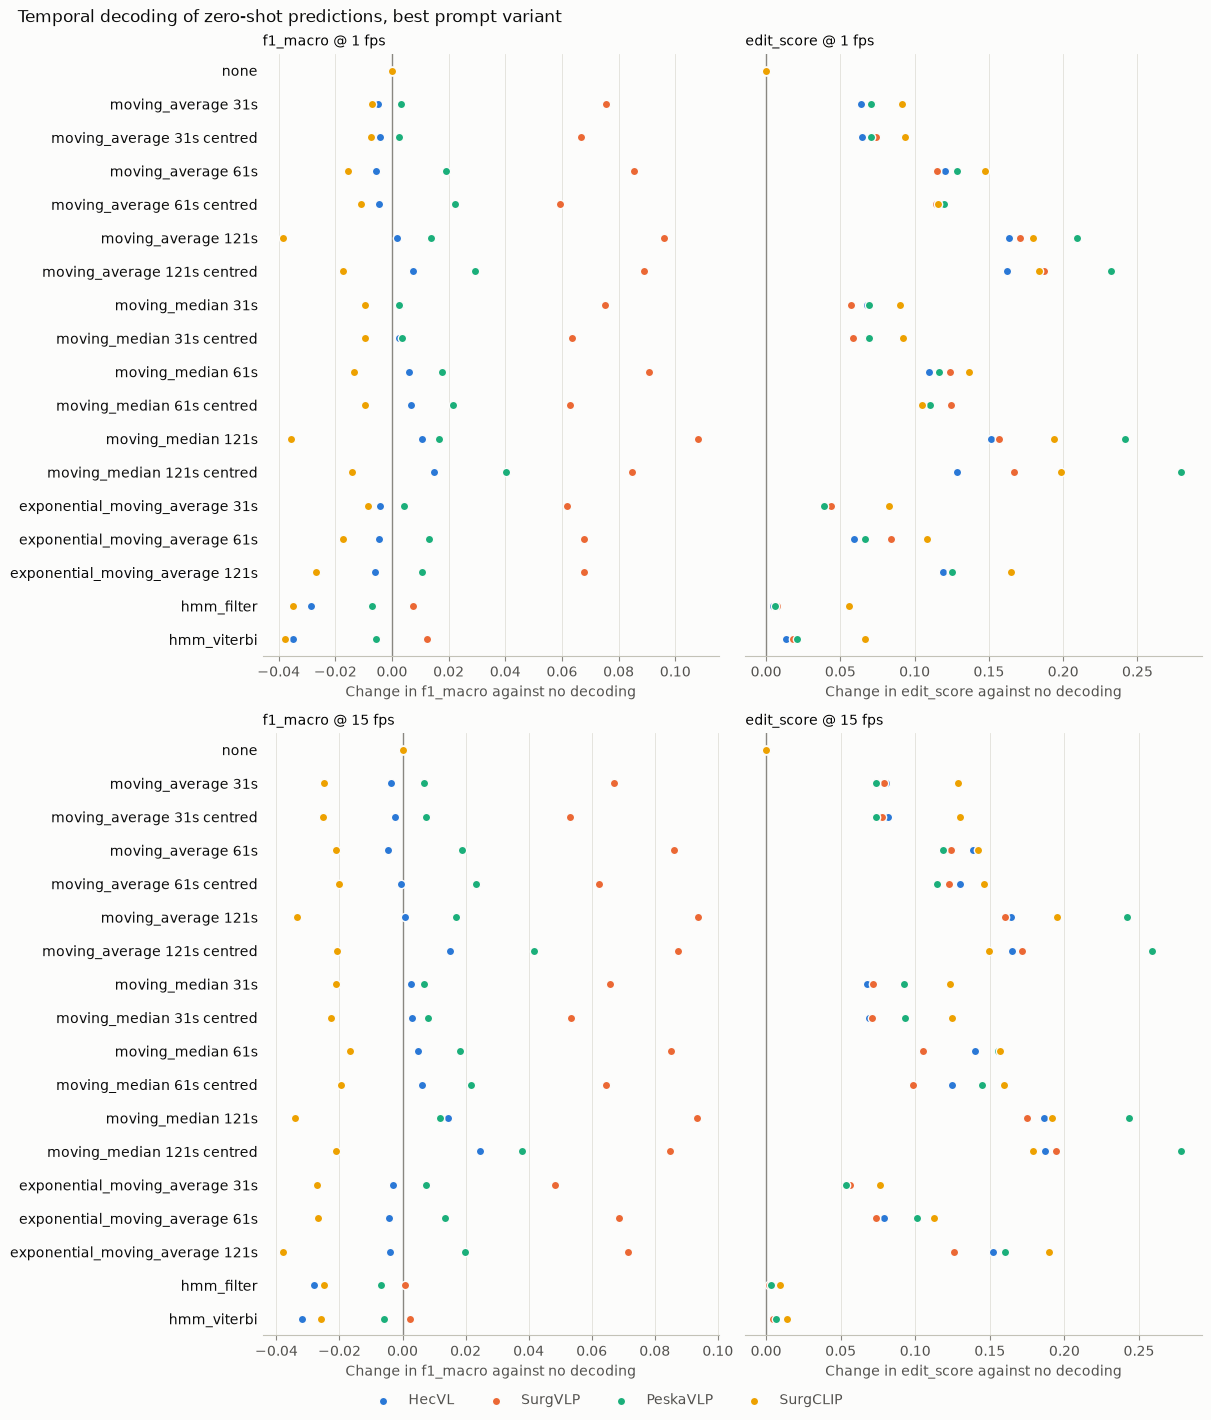

best decoding  f1_macro none  f1_macro decoded  \
model    fps                                                                  
HecVL    1.0    moving_median 121s centred          0.129             0.143   
         15.0   moving_median 121s centred          0.127             0.152   
SurgVLP  1.0            moving_median 121s          0.231             0.339   
         15.0          moving_average 121s          0.230             0.324   
PeskaVLP 1.0    moving_median 121s centred          0.209             0.250   
         15.0  moving_average 121s centred          0.207             0.249   
SurgCLIP 1.0                          none          0.199             0.199   
         15.0                         none          0.174             0.174   

               edit_score none  edit_score decoded  
model    fps                                        
HecVL    1.0             0.010               0.138  
         15.0            0.002               0.188  
SurgVLP  1.0             0.008               0.164  
         15.0            0.001               0.161  
PeskaVLP 1.0             0.010               0.289  
         15.0            0.002               0.260  
SurgCLIP 1.0             0.057               0.057  
         15.0            0.007               0.007

In [10]:
decoding_metrics = ["f1_macro", "edit_score"]
decoding_scores = best_results.pivot_table(index="decoding", columns=["model", "fps"], values=decoding_metrics, aggfunc="mean")
decoding_scores = decoding_scores.reindex(index=decoding_order)
decoding_gain = decoding_scores - decoding_scores.loc["none"]

fig, axes = plt.subplots(
    len(fps_values), len(decoding_metrics), figsize=(12, (0.32 * len(decoding_order) + 1) * len(fps_values) + 0.6),
    layout="constrained", sharey=True, squeeze=False,
)
for row, fps in enumerate(fps_values):
    for ax, metric in zip(axes[row], decoding_metrics, strict=True):
        clean_axes(ax, grid_axis="x")
        positions = np.arange(len(decoding_order))
        for model in models:
            if (metric, model, fps) not in decoding_gain.columns:
                continue
            ax.scatter(
                decoding_gain[(metric, model, fps)], positions, s=36, color=MODEL_COLORS[model], edgecolor=SURFACE,
                linewidth=1, zorder=3, label=model,
            )
        ax.axvline(0, color=MUTED_INK, linewidth=1)
        ax.set_yticks(positions, labels=decoding_order)
        ax.set_ylim(len(decoding_order) - 0.5, -0.5)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0, labelcolor=INK)
        ax.set_xlabel(f"Change in {metric} against no decoding")
        ax.set_title(f"{metric} @ {fps:g} fps", loc="left", fontsize=10)
figure_legend(fig, axes)
fig.suptitle("Temporal decoding of zero-shot predictions, best prompt variant", x=0.01, ha="left", color=INK)
plt.show()

best_decoding = decoding_scores["f1_macro"].idxmax()
decoding_summary = pd.DataFrame(
    {
        "best decoding": best_decoding,
        "f1_macro none": decoding_scores["f1_macro"].loc["none"],
        "f1_macro decoded": decoding_scores["f1_macro"].max(),
        "edit_score none": decoding_scores["edit_score"].loc["none"],
        "edit_score decoded": [decoding_scores[("edit_score", *key)][label] for key, label in best_decoding.items()],
    }
)
decoding_summary.reindex(models, level="model").round(3)

## Predicted timelines

Zero-shot phase sequence against the ground truth per surgery, raw and decoded.

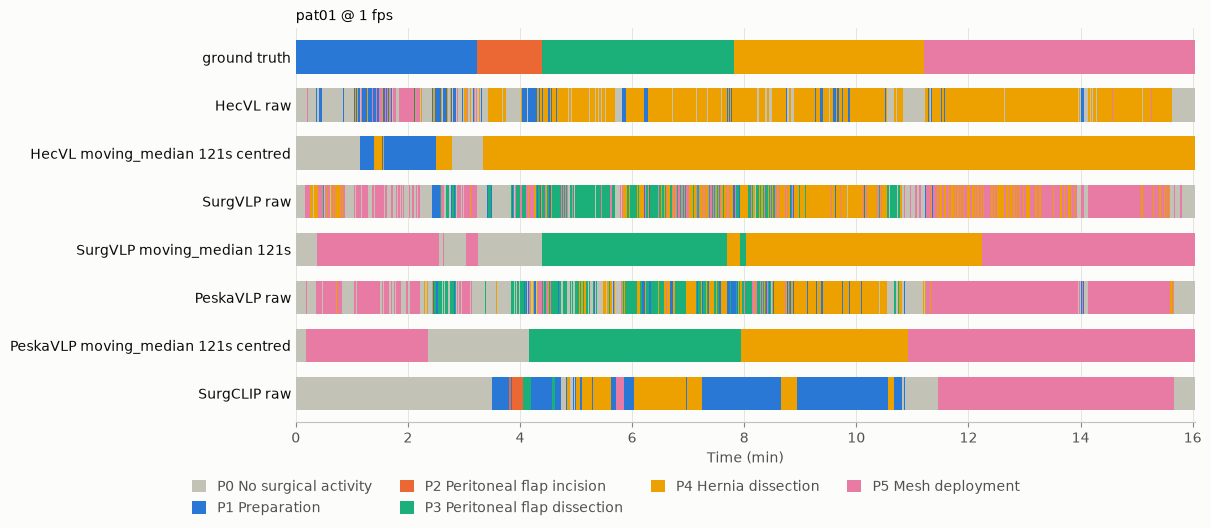

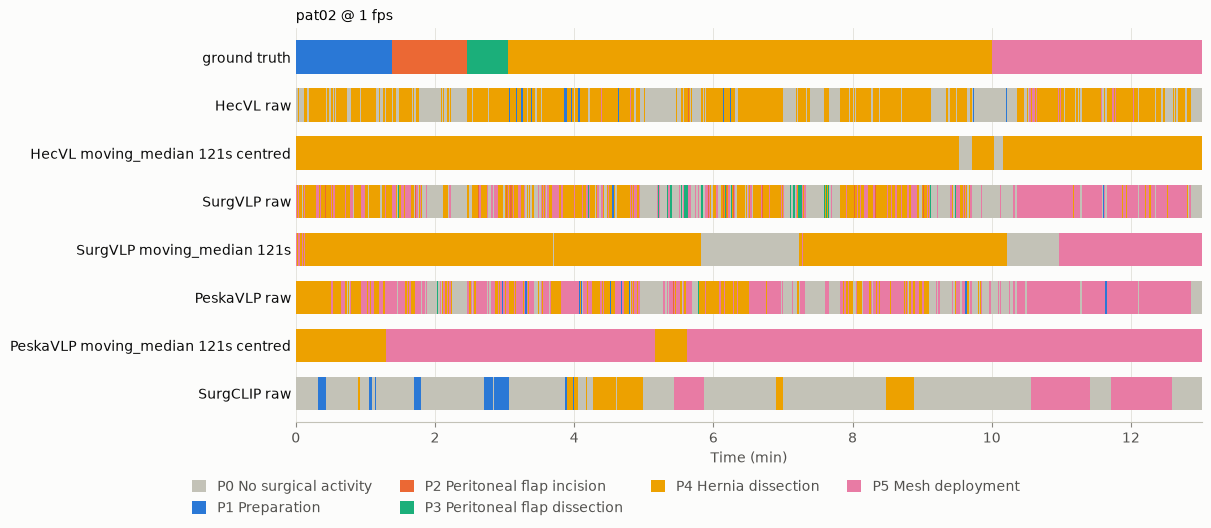

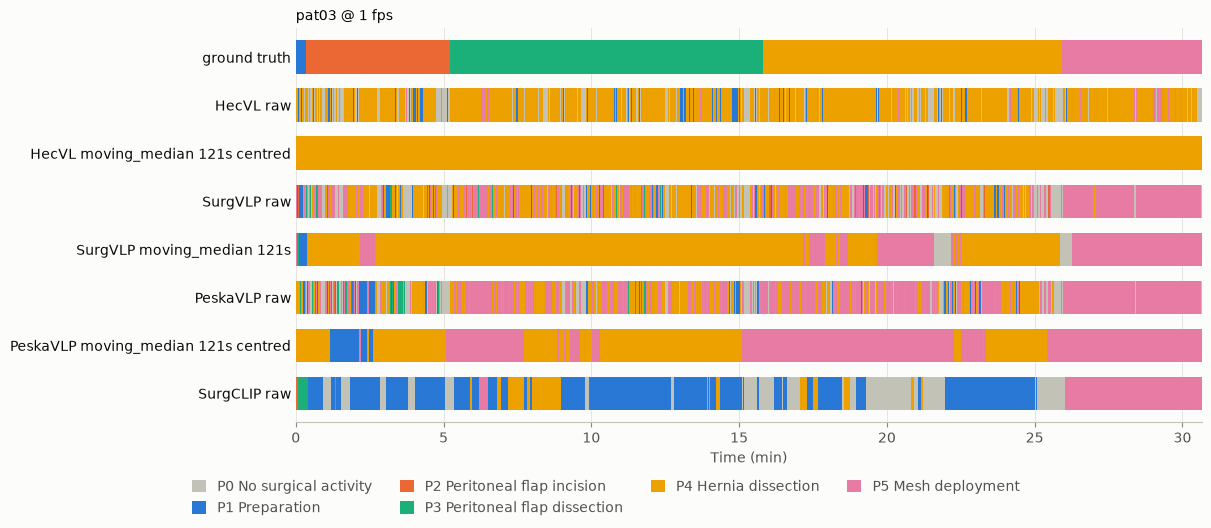

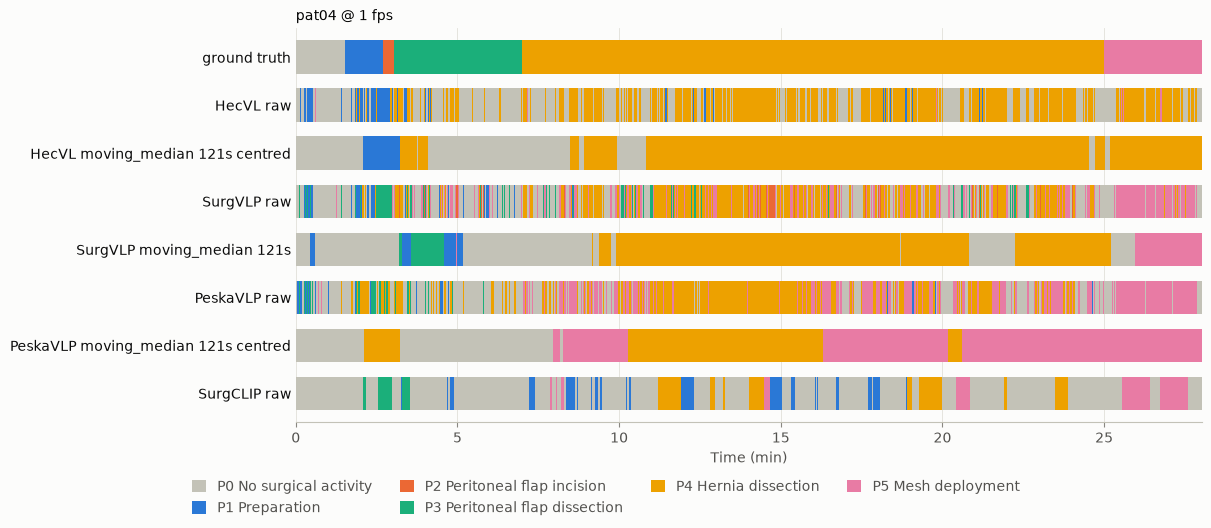

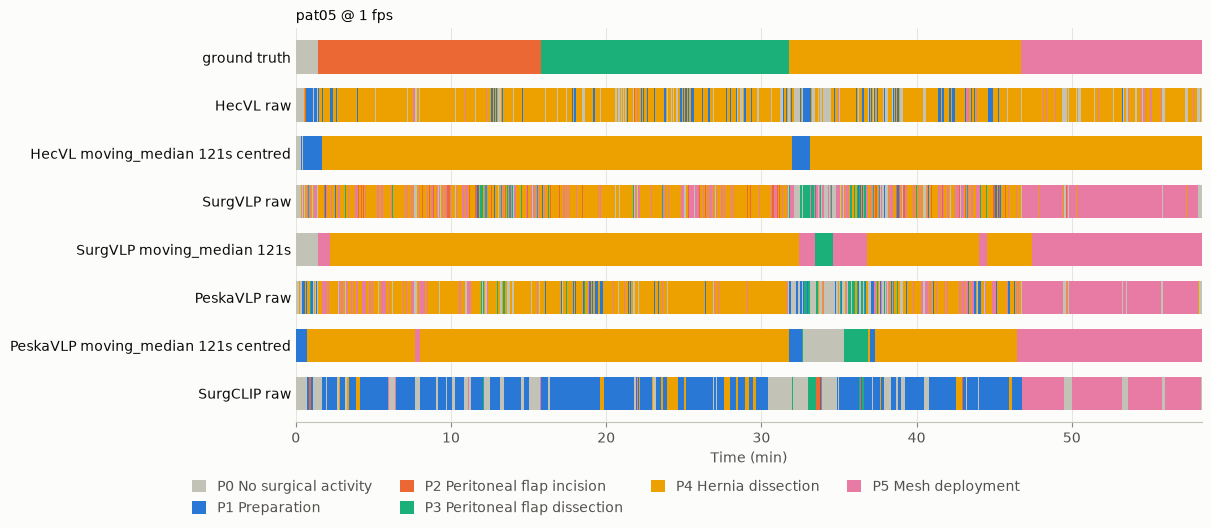

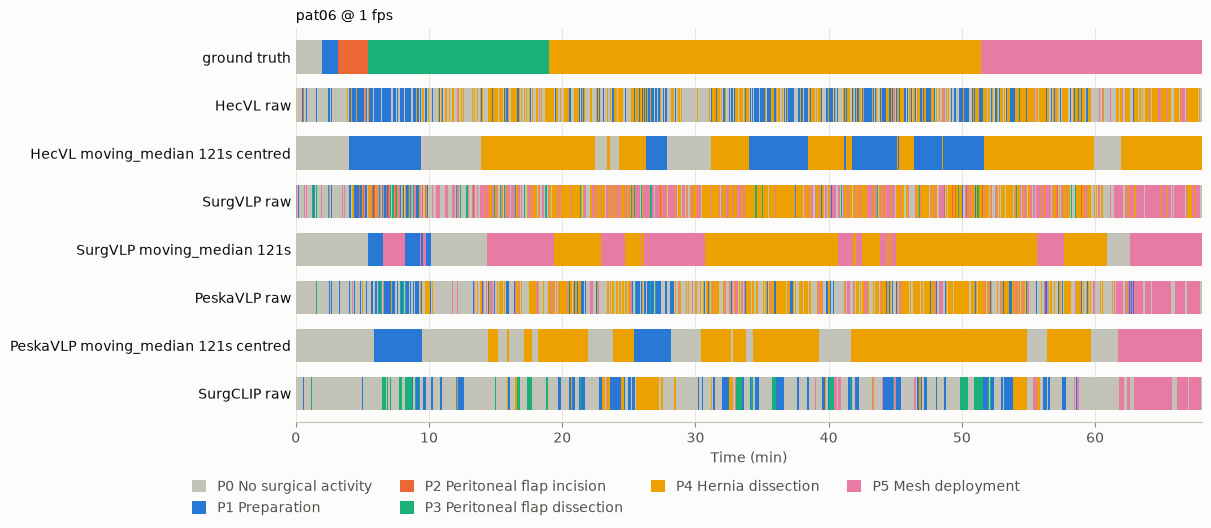

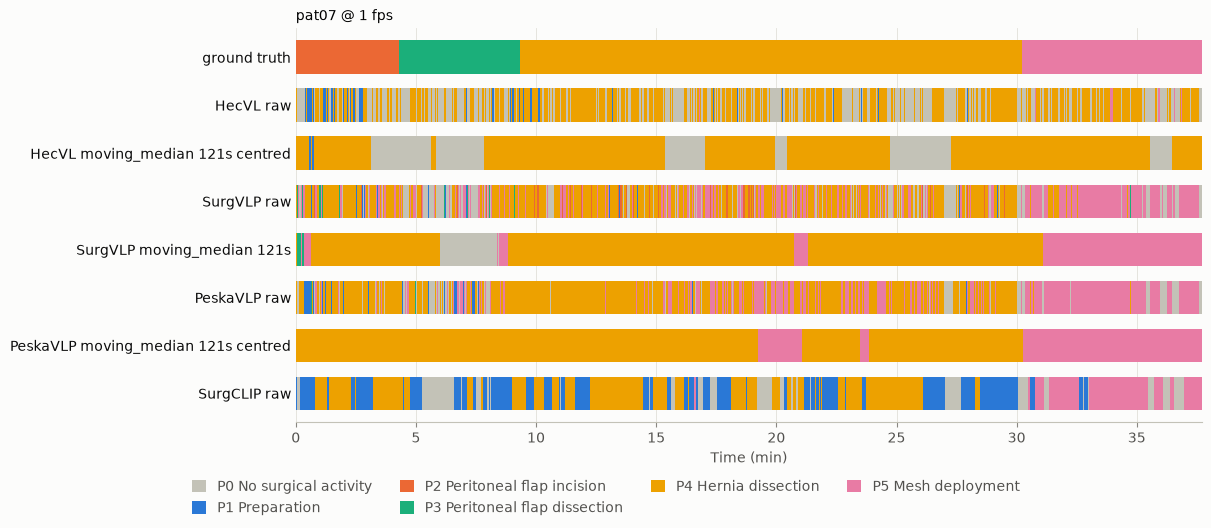

In [11]:
timeline_fps = TIMELINE_FPS if TIMELINE_FPS in fps_values else fps_values[0]
hmms = leave_one_out_hmms(
    {surgery_id: surgery.labels[surgery.labelled] for surgery_id, surgery in surgeries[timeline_fps].items()},
    num_phases,
    run["hmm_pseudocount"],
)
for surgery_id, surgery in surgeries[timeline_fps].items():
    rows = {"ground truth": surgery.labels}
    for model in models:
        key = (model, timeline_fps, best_variant.get((model, timeline_fps)))
        if key not in probabilities or surgery_id not in probabilities[key]:
            continue
        p = probabilities[key][surgery_id]
        rows[f"{model} raw"] = p.argmax(axis=1)
        label = best_decoding[(model, timeline_fps)]
        decoding = decodings_by_label[label]
        if decoding.method != "none":
            hmm = hmms[surgery_id] if decoding.method in HMM_METHODS else None
            rows[f"{model} {label}"] = decoding.apply(p, timeline_fps, hmm)
    ax = plot_timeline(rows, phase_names, colors, timeline_fps)
    ax.set_title(f"{surgery_id} @ {timeline_fps:g} fps", loc="left", fontsize=10)
    plt.show()

## Per-surgery variability

Spread of macro F1 across surgeries per model. Whether some surgeries are consistently harder.

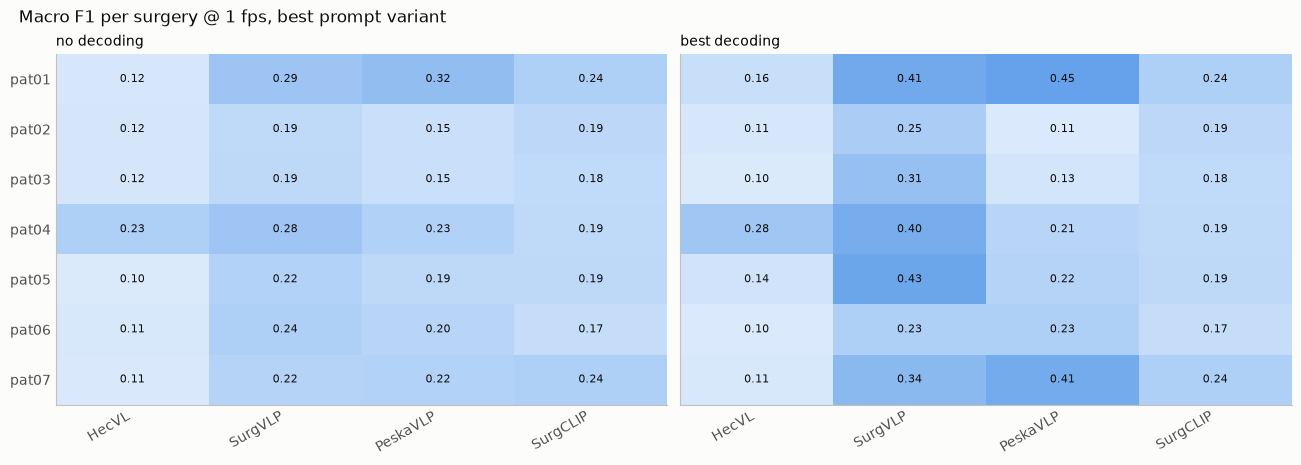

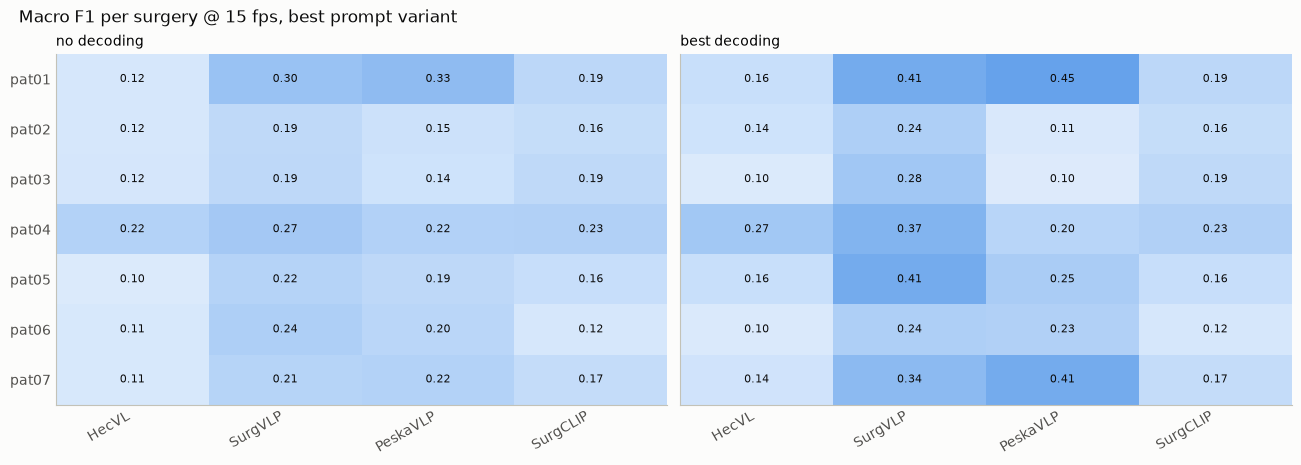

,minutes,f1_macro mean,f1_macro std,f1_macro min,f1_macro max,f1_macro decoded mean,rank
pat01,16.033,0.237,0.088,0.115,0.329,0.308,1
pat04,28.017,0.233,0.030,0.187,0.283,0.267,2
pat07,37.700,0.188,0.051,0.109,0.237,0.269,3
pat06,68.000,0.172,0.055,0.109,0.237,0.178,4
pat05,58.367,0.171,0.047,0.101,0.220,0.244,5
pat03,30.650,0.159,0.032,0.118,0.191,0.172,6
pat02,13.017,0.158,0.031,0.115,0.194,0.164,7


In [12]:
decoded_best = best_results[
    [best_decoding.get((m, f)) == d for m, f, d in zip(best_results["model"], best_results["fps"], best_results["decoding"], strict=True)]
]
surgery_ids = sorted(results["surgery_id"].unique())
views = {"no decoding": best_raw, "best decoding": decoded_best}

for fps in fps_values:
    fig, axes = plt.subplots(
        1, len(views), figsize=(1.3 * len(models) * len(views) + 2.5, 0.42 * len(surgery_ids) + 1.6),
        layout="constrained", sharey=True, squeeze=False,
    )
    for ax, (name, frame) in zip(axes[0], views.items(), strict=True):
        matrix = (
            frame[frame["fps"] == fps]
            .pivot_table(index="surgery_id", columns="model", values="f1_macro")
            .reindex(index=surgery_ids, columns=models)
        )
        style_axes(ax)
        ax.imshow(matrix.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
        annotate_heatmap(ax, matrix.to_numpy())
        ax.set_xticks(range(len(models)), labels=models, rotation=30, ha="right")
        ax.set_yticks(range(len(surgery_ids)), labels=surgery_ids)
        ax.tick_params(length=0)
        ax.set_title(name, loc="left", fontsize=10)
    fig.suptitle(f"Macro F1 per surgery @ {fps:g} fps, best prompt variant", x=0.01, ha="left", color=INK)
    plt.show()

surgery_minutes = pd.Series(
    {s: len(y) / fps_values[0] / 60 for s, y in labels[fps_values[0]].items()}, name="minutes"
)
per_surgery = best_raw.groupby("surgery_id")["f1_macro"].agg(["mean", "std", "min", "max"]).add_prefix("f1_macro ")
per_surgery["f1_macro decoded mean"] = decoded_best.groupby("surgery_id")["f1_macro"].mean()
per_surgery["rank"] = per_surgery["f1_macro mean"].rank(ascending=False).astype(int)
pd.concat([surgery_minutes, per_surgery], axis=1).sort_values("rank").round(3)

## Model comparison

Summary table of the metrics above, one row per model, FPS and prompt style.

In [13]:
best_decoding_per_variant = (
    results.groupby(["model", "fps", "variant", "decoding"])["f1_macro"].mean().groupby(["model", "fps", "variant"]).agg(
        ["idxmax", "max"]
    )
)
comparison = (
    raw.groupby(["model", "fps", "variant"])[SUMMARY_METRICS].mean()
    .join(
        pd.DataFrame(
            {
                "best decoding": best_decoding_per_variant["idxmax"].map(lambda index: index[3]),
                "f1_macro decoded": best_decoding_per_variant["max"],
            }
        )
    )
    .join(calibration[["mean confidence", "ECE"]])
    .join(bias[["top share", "normalised entropy", "total variation"]])
)
comparison = comparison.reindex(pd.MultiIndex.from_tuples(keys, names=comparison.index.names))
comparison.round(3)

accuracy  f1_macro  edit_score  f1_at_25  \
model    fps  variant                                                           
HecVL    1.0  narrative                 0.130     0.105       0.008     0.003   
              descriptive               0.290     0.129       0.010     0.001   
              narrative+descriptive     0.100     0.090       0.010     0.002   
         15.0 narrative                 0.131     0.105       0.001     0.000   
              descriptive               0.290     0.127       0.002     0.000   
              narrative+descriptive     0.100     0.090       0.001     0.000   
SurgVLP  1.0  narrative                 0.337     0.203       0.007     0.002   
              descriptive               0.367     0.221       0.008     0.000   
              narrative+descriptive     0.391     0.231       0.008     0.002   
         15.0 narrative                 0.334     0.200       0.001     0.000   
              descriptive               0.367     0.218       0.001     0.000   
              narrative+descriptive     0.391     0.230       0.001     0.000   
PeskaVLP 1.0  narrative                 0.334     0.199       0.009     0.004   
              descriptive               0.406     0.208       0.011     0.005   
              narrative+descriptive     0.385     0.209       0.010     0.005   
         15.0 narrative                 0.333     0.199       0.001     0.000   
              descriptive               0.403     0.207       0.002     0.001   
              narrative+descriptive     0.381     0.207       0.002     0.000   
SurgCLIP 1.0  narrative                 0.251     0.199       0.057     0.028   
              descriptive               0.258     0.199       0.111     0.061   
              narrative+descriptive     0.246     0.197       0.071     0.051   
         15.0 narrative                 0.185     0.174       0.007     0.001   
              descriptive               0.177     0.170       0.021     0.003   
              narrative+descriptive     0.170     0.168       0.010     0.001   

                                                       best decoding  \
model    fps  variant                                                  
HecVL    1.0  narrative              exponential_moving_average 121s   
              descriptive                 moving_median 121s centred   
              narrative+descriptive        moving_median 61s centred   
         15.0 narrative              exponential_moving_average 121s   
              descriptive                 moving_median 121s centred   
              narrative+descriptive       moving_median 121s centred   
SurgVLP  1.0  narrative                   moving_median 121s centred   
              descriptive                        moving_average 121s   
              narrative+descriptive               moving_median 121s   
         15.0 narrative                   moving_median 121s centred   
              descriptive                        moving_average 121s   
              narrative+descriptive              moving_average 121s   
PeskaVLP 1.0  narrative                                         none   
              descriptive                 moving_median 121s centred   
              narrative+descriptive       moving_median 121s centred   
         15.0 narrative                                         none   
              descriptive                 moving_median 121s centred   
              narrative+descriptive      moving_average 121s centred   
SurgCLIP 1.0  narrative                                         none   
              descriptive                 moving_average 31s centred   
              narrative+descriptive        moving_median 31s centred   
         15.0 narrative                                         none   
              descriptive                                       none   
              narrative+descriptive                             none   

                                     f1_macro decoded  me